In [1]:
# ===== D-0: Settings, file discovery, load, merge, basic checks =====
import os
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

ROOT = Path(r"D:\Siam\Thesis_GeoAI")
OUT_DIR = ROOT / "05_models" / "diagnostics_v03"
OUT_DIR.mkdir(parents=True, exist_ok=True)
SKIP_DIRS = {"osm", ".ipynb_checkpoints", "__pycache__", ".git"}

MASTER_NAME = "master_v06_20261020.csv"
LABEL_NAME = "Label_Flooded_Event_v01.csv"
GRID_NAME = "grid_250m_v01.gpkg"
HAZARD_DIR = ROOT / "05_models" / "final_v02"
HAZARD_KEY = "hazard_predictions"

C_TREE = "Tree_Fraction"
C_MANG = "Mangrove_Fraction_GMW"
C_BLDG = "Building_Count"
C_POP = "Population_Count"
C_ELEV = "Elevation_Mean_m"
C_SLOPE = "Slope_Mean_deg"
C_RIVER = "Distance_to_River_m"
C_NDVI = "NDVI_Mean"
C_WATER = "Is_Water"

ID_CANDIDATES = ["Grid_ID", "Cell_ID", "GridID", "grid_id", "cell_id", "ID", "id"]
EVENT_CANDIDATES = ["Event", "Event_Name", "Cyclone", "event", "Event_ID"]
N_MODEL_CELLS_EXPECTED = 160874
N_LABEL_ROWS_EXPECTED = 457251
BLOCK_M = 15000
CELL_M = 250
TARGET_EPSG = 32646


def find_one(root, name=None, key=None, ext=None):
    hits = []
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in SKIP_DIRS]
        for f in filenames:
            if name is not None and f == name:
                hits.append(Path(dirpath) / f)
            elif key is not None and key in f and (ext is None or f.endswith(ext)):
                hits.append(Path(dirpath) / f)
    if not hits:
        raise FileNotFoundError(f"Not found under {root}: {name or key}")
    if len(hits) > 1:
        print(f"  WARNING: {len(hits)} matches for {name or key}; using the first:")
        for h in hits:
            print("     ", h)
    return hits[0]


def pick(cols, candidates, what):
    for c in candidates:
        if c in cols:
            return c
    raise KeyError(f"No {what} column found. Available columns: {list(cols)}")


def norm_id(s):
    if pd.api.types.is_numeric_dtype(s):
        assert s.notna().all(), "ID column has NaN"
        assert (s == s.round()).all(), "ID column has non-integer values"
        return s.astype("int64")
    return s.astype(str)


p_master = find_one(ROOT, name=MASTER_NAME)
p_label = find_one(ROOT, name=LABEL_NAME)
p_grid = find_one(ROOT, name=GRID_NAME)
p_haz = find_one(HAZARD_DIR, key=HAZARD_KEY, ext=".csv")
for k, p in [("master", p_master), ("label", p_label), ("grid", p_grid), ("hazard", p_haz)]:
    print(f"{k:7s}: {p}")

master = pd.read_csv(p_master)
label = pd.read_csv(p_label)
haz = pd.read_csv(p_haz)
print("\nmaster shape:", master.shape)
print("label shape :", label.shape, "| columns:", list(label.columns))
print("hazard shape:", haz.shape, "| columns:", list(haz.columns))

# --- ID columns ---
ID = pick(master.columns, ID_CANDIDATES, "master ID")
label = label.rename(columns={pick(label.columns, ID_CANDIDATES, "label ID"): ID})
haz = haz.rename(columns={pick(haz.columns, ID_CANDIDATES, "hazard ID"): ID})
for d in (master, label, haz):
    d[ID] = norm_id(d[ID])
print("\nID column:", ID)

# --- Required master columns ---
req = [C_TREE, C_MANG, C_BLDG, C_POP, C_ELEV, C_SLOPE, C_RIVER, C_NDVI, C_WATER]
missing = [c for c in req if c not in master.columns]
if missing:
    print("MISSING columns:", missing)
    print("Columns with 'mang', 'built', 'build', 'tree':",
          [c for c in master.columns if any(k in c.lower() for k in ["mang", "built", "build", "tree"])])
    raise KeyError("Fix column names in settings and rerun D-0")
dist_cols = [c for c in master.columns if "district" in c.lower() and master[c].dtype == object]
C_DIST = dist_cols[0] if dist_cols else None
print("District column:", C_DIST)

# --- Event and label columns ---
EV = pick(label.columns, EVENT_CANDIDATES, "event")
other = [c for c in label.columns if c not in (ID, EV)]
bin_cols = [c for c in other if pd.api.types.is_numeric_dtype(label[c])
            and set(pd.unique(label[c].dropna())) <= {0, 1}]
assert bin_cols, f"No binary label column found in {other}"
pref = [c for c in bin_cols if "label" in c.lower() or "flood" in c.lower()]
LAB = pref[0] if pref else bin_cols[0]
print("Event column:", EV, "| label column:", LAB, "| other binary candidates:", bin_cols)

# --- Hazard column ---
hc = [c for c in haz.columns if c != ID and pd.api.types.is_numeric_dtype(haz[c])
      and haz[c].dropna().between(0, 1).all() and haz[c].nunique() > 2]
assert hc, "No probability column found in hazard file"
pref = [c for c in hc if "lgbm" in c.lower()]
HAZ = pref[0] if pref else hc[0]
print("Hazard column used:", HAZ, "| probability candidates:", hc)

# --- Checks ---
print("\n--- CHECKS ---")
print("master duplicate IDs:", master[ID].duplicated().sum())
print("label rows:", len(label), "(expected", N_LABEL_ROWS_EXPECTED, ")")
print("label duplicate (ID, event):", label.duplicated([ID, EV]).sum())
print("label NaN values:", label[LAB].isna().sum())
print("hazard duplicate IDs:", haz[ID].duplicated().sum())
print("\nPositive rate by event (%):")
print((label.groupby(EV)[LAB].agg(["size", "sum", "mean"]).assign(mean=lambda t: 100 * t["mean"])).round(3))

wide = label.pivot_table(index=ID, columns=EV, values=LAB, aggfunc="first")
EVENTS = [f"Lab_{e}" for e in wide.columns]
wide.columns = EVENTS
wide = wide.reset_index()

model = master.loc[master[C_WATER] == 0].copy()
assert len(model) == N_MODEL_CELLS_EXPECTED, f"Model cells = {len(model)}, expected {N_MODEL_CELLS_EXPECTED}"
df = model.merge(haz[[ID, HAZ]], on=ID, how="left").merge(wide, on=ID, how="left")
assert len(df) == N_MODEL_CELLS_EXPECTED, "Merge changed row count"
df["N_Events_Labeled"] = df[EVENTS].notna().sum(axis=1)
df["N_Events_Flooded"] = df[EVENTS].sum(axis=1, min_count=1).fillna(0)
df["Label_Freq"] = df["N_Events_Flooded"] / df["N_Events_Labeled"].replace(0, np.nan)

# --- Grid centroids ---
grid = gpd.read_file(p_grid)
assert grid.crs is not None and grid.crs.to_epsg() == TARGET_EPSG, f"Grid CRS is {grid.crs}"
gid = pick(grid.columns, ID_CANDIDATES, "grid ID")
cent = grid.geometry.centroid
xy = pd.DataFrame({ID: norm_id(grid[gid]), "X_m": cent.x.values, "Y_m": cent.y.values})
assert not xy[ID].duplicated().any(), "Duplicate IDs in grid"
df = df.merge(xy, on=ID, how="left")
assert df["X_m"].notna().all(), "Some model cells have no grid geometry"

print("\nModel cells:", len(df))
print("Model cells with no label row at all:", (df["N_Events_Labeled"] == 0).sum())
print("Cells labeled in 1/2/3 events:", df["N_Events_Labeled"].value_counts().sort_index().to_dict())
print("Model cells missing v02 hazard:", df[HAZ].isna().sum())
for c in [C_TREE, C_MANG, C_BLDG, C_POP]:
    print(f"{c:24s} min={df[c].min():.4f} max={df[c].max():.4f} NaN={df[c].isna().sum()}")
print("\nD-0 OK")

master : D:\Siam\Thesis_GeoAI\04_master_table\master_v06_20261020.csv
label  : D:\Siam\Thesis_GeoAI\03_features\Label_Flooded_Event_v01.csv
grid   : D:\Siam\Thesis_GeoAI\02_boundary_grid\grid_250m_v01.gpkg
hazard : D:\Siam\Thesis_GeoAI\05_models\final_v02\hazard_predictions_v02.csv

master shape: (218035, 65)
label shape : (457251, 7) | columns: ['Grid_ID', 'Event_ID', 'Flooded_Event', 'Weak_Label_Flag', 'District', 'Evid_Flood_Fraction', 'Control_Positive']
hazard shape: (160874, 6) | columns: ['Grid_ID', 'Hazard_Prob_RF', 'Hazard_Prob_LGBM', 'Hazard_Prob_Logistic', 'Hazard_Score_FR', 'Hazard_Score_ElevOnly']

ID column: Grid_ID
District column: District
Event column: Event_ID | label column: Flooded_Event | other binary candidates: ['Flooded_Event', 'Weak_Label_Flag', 'Control_Positive']
Hazard column used: Hazard_Prob_LGBM | probability candidates: ['Hazard_Prob_RF', 'Hazard_Prob_LGBM', 'Hazard_Prob_Logistic']

--- CHECKS ---
master duplicate IDs: 0
label rows: 457251 (expected 4572

In [2]:
# ===== D-1: Label rate by feature bins (SAR observability test) =====
for c in [C_TREE, C_MANG]:
    if df[c].max() > 1.5:
        print(f"WARNING: {c} max = {df[c].max():.2f}; looks like percent, not fraction. Tell me before continuing.")


def rate_table(data, feat, bins=None, q=None):
    b = (pd.cut(data[feat], bins=bins, include_lowest=True) if bins is not None
         else pd.qcut(data[feat], q=q, duplicates="drop"))
    g = data.groupby(b, observed=False)
    t = pd.DataFrame({"N_Cells": g.size()})
    t["Pct_Cells"] = 100 * t["N_Cells"] / len(data)
    t["Pct_Population"] = 100 * g[C_POP].sum() / data[C_POP].sum()
    for e in EVENTS:
        t[f"{e}_Pct"] = 100 * g[e].mean()
    n = g["N_Events_Labeled"].sum()
    t["Pooled_Rate_Pct"] = 100 * g["N_Events_Flooded"].sum() / n.replace(0, np.nan)
    t["Pct_Cell_Events_Labeled"] = 100 * n / (len(EVENTS) * t["N_Cells"]).replace(0, np.nan)
    return t.round(3)


tabs = {
    "tree": rate_table(df, C_TREE, bins=[0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0]),
    "tree_fine_0.4_0.6": rate_table(df, C_TREE, bins=list(np.round(np.arange(0.40, 0.601, 0.025), 3))),
    "mangrove": rate_table(df, C_MANG, bins=[-0.001, 0, 0.05, 0.1, 0.3, 0.5, 1.0]),
    "building": rate_table(df, C_BLDG, bins=[-0.5, 0.5, 2.5, 5.5, 10.5, 20.5, 50.5, np.inf]),
    "elevation": rate_table(df, C_ELEV, q=10),
    "ndvi": rate_table(df, C_NDVI, q=10),
    "river": rate_table(df, C_RIVER, q=10),
}
for k, t in tabs.items():
    t.to_csv(OUT_DIR / f"D1_rate_by_{k}.csv")
for k in ["tree", "tree_fine_0.4_0.6", "mangrove", "building"]:
    print(f"\n=== Label rate by {k} ===")
    print(tabs[k].to_string())
for k in ["elevation", "ndvi", "river"]:
    print(f"\n=== Label rate by {k} deciles (compact) ===")
    print(tabs[k][["N_Cells", "Pooled_Rate_Pct"]].to_string())

# Hard-zero check: physics gives noisy small positives; a pipeline mask gives exact zeros and a cliff
canopy = df[df[C_TREE] >= 0.5]
print("\n=== Hard-zero check (Tree_Fraction >= 0.5) ===")
print("cells:", len(canopy), "| with any label row:", (canopy["N_Events_Labeled"] > 0).sum())
for e in EVENTS:
    print(f"  {e}: unique values = {sorted(canopy[e].dropna().unique().tolist())}, positives = {int(canopy[e].sum())}")
print("Tree_Fraction of model cells with NO label row:")
print(df.loc[df["N_Events_Labeled"] == 0, C_TREE].describe().round(3).to_string())


=== Label rate by tree ===
                N_Cells  Pct_Cells  Pct_Population  Lab_Amphan_Pct  Lab_Remal_Pct  Lab_Yaas_Pct  Pooled_Rate_Pct  Pct_Cell_Events_Labeled
Tree_Fraction                                                                                                                            
(-0.001, 0.05]    55053     34.221           4.950           5.882         17.621         3.514            9.006                   88.600
(0.05, 0.1]        7250      4.507           2.616           5.849         24.508         3.413           11.256                   91.738
(0.1, 0.2]        11990      7.453           5.679           3.747         19.351         2.262            8.453                   94.387
(0.2, 0.3]        10898      6.774           6.477           2.336         11.739         1.235            5.103                   96.614
(0.3, 0.4]        10758      6.687           7.724           0.768          4.258         0.294            1.774                   98.011
(0.4, 

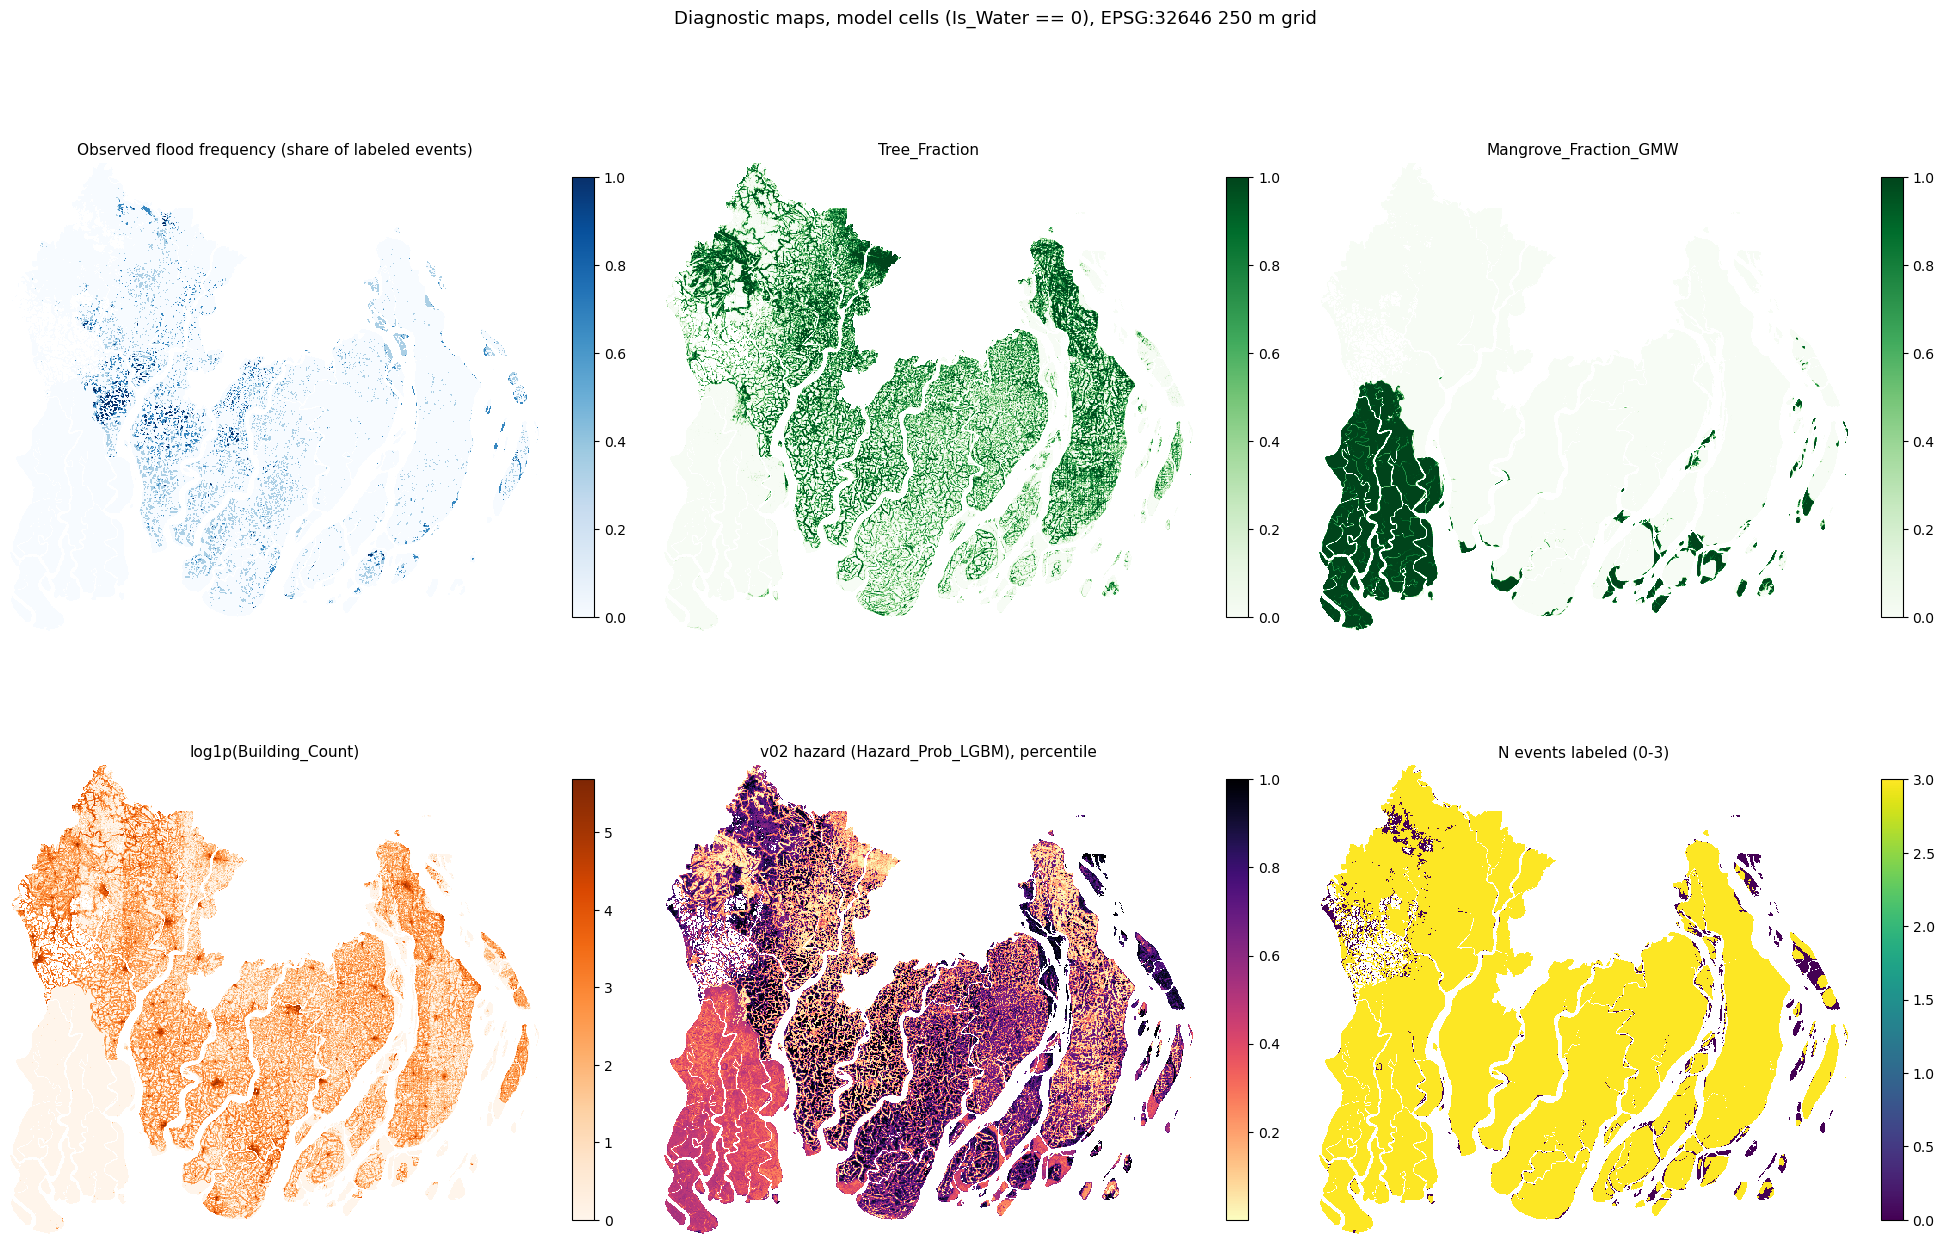

Saved: D:\Siam\Thesis_GeoAI\05_models\diagnostics_v03\D2_maps_label_tree_mangrove_building_hazard.png


In [3]:
# ===== D-2: Maps (label frequency, tree, mangrove, buildings, v02 hazard, label coverage) =====
xmin, ymax = df["X_m"].min(), df["Y_m"].max()
ci = np.round((df["X_m"] - xmin) / CELL_M).astype(int).values
ri = np.round((ymax - df["Y_m"]) / CELL_M).astype(int).values
H, W = ri.max() + 1, ci.max() + 1
assert not pd.Series(list(zip(ri, ci))).duplicated().any(), "Two cells map to one pixel; grid not aligned"


def to_img(v):
    img = np.full((H, W), np.nan)
    img[ri, ci] = v
    return img


panels = [
    (df["Label_Freq"].values, "Observed flood frequency (share of labeled events)", "Blues"),
    (df[C_TREE].values, "Tree_Fraction", "Greens"),
    (df[C_MANG].values, "Mangrove_Fraction_GMW", "Greens"),
    (np.log1p(df[C_BLDG].values), "log1p(Building_Count)", "Oranges"),
    (df[HAZ].rank(pct=True).values, f"v02 hazard ({HAZ}), percentile", "magma_r"),
    (df["N_Events_Labeled"].values, "N events labeled (0-3)", "viridis"),
]
fig, axes = plt.subplots(2, 3, figsize=(20, 14))
for ax, (v, title, cmap) in zip(axes.ravel(), panels):
    im = ax.imshow(to_img(v), cmap=cmap, interpolation="nearest")
    ax.set_title(title, fontsize=11)
    ax.set_axis_off()
    fig.colorbar(im, ax=ax, shrink=0.6)
fig.suptitle("Diagnostic maps, model cells (Is_Water == 0), EPSG:32646 250 m grid", fontsize=13)
fig.tight_layout()
p_fig = OUT_DIR / "D2_maps_label_tree_mangrove_building_hazard.png"
fig.savefig(p_fig, dpi=150)
plt.show()
print("Saved:", p_fig)

In [4]:
# ===== D-3: Population by v02 hazard class =====
haz_bins = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]
g = df.groupby(pd.cut(df[HAZ], haz_bins, include_lowest=True), observed=False)
t3 = pd.DataFrame({
    "N_Cells": g.size(),
    "Population": g[C_POP].sum().round(0),
    "Mean_Tree_Fraction": g[C_TREE].mean(),
    "Pct_Cells_Tree_GE_0.3": g[C_TREE].apply(lambda s: 100 * (s >= 0.3).mean()),
    "Pooled_Label_Rate_Pct": 100 * g["N_Events_Flooded"].sum() / g["N_Events_Labeled"].sum().replace(0, np.nan),
})
t3["Pct_Population"] = 100 * t3["Population"] / df[C_POP].sum()
t3 = t3.round(3)
t3.to_csv(OUT_DIR / "D3_population_by_hazard_bin.csv")
print("=== Population by v02 hazard probability bin ===")
print(t3.to_string())

pop_tot = df[C_POP].sum()
print(f"\nTotal population (model cells): {pop_tot:,.0f}")
for thr in [0.3, 0.5]:
    m = df[C_TREE] >= thr
    print(f"Tree_Fraction >= {thr}: {m.mean() * 100:.1f}% of cells, {100 * df.loc[m, C_POP].sum() / pop_tot:.1f}% of population")
print("\nMean v02 hazard by Tree_Fraction bin (what the model learned):")
print(df.groupby(pd.cut(df[C_TREE], [0, 0.1, 0.3, 0.5, 1.0], include_lowest=True), observed=False)[HAZ]
      .agg(["mean", "median"]).round(4).to_string())

=== Population by v02 hazard probability bin ===
                  N_Cells  Population  Mean_Tree_Fraction  Pct_Cells_Tree_GE_0.3  Pooled_Label_Rate_Pct  Pct_Population
Hazard_Prob_LGBM                                                                                                       
(-0.001, 0.01]     101901   6102568.0               0.483                 69.046                  0.002          78.996
(0.01, 0.02]         5711    259045.0               0.251                 42.199                  0.301           3.353
(0.02, 0.05]        11658    435096.0               0.177                 17.808                  1.784           5.632
(0.05, 0.1]         12309    380461.0               0.117                  5.167                  6.240           4.925
(0.1, 0.2]          15636    361641.0               0.065                  1.030                 14.593           4.681
(0.2, 0.5]          12919    180989.0               0.025                  0.279                 31.390        

In [5]:
# ===== D-4: Block bias (15 km diagnostic blocks; origin may differ from v02 CV blocks) =====
df["Block_ID"] = (np.floor(df["X_m"] / BLOCK_M).astype(int).astype(str) + "_" +
                  np.floor(df["Y_m"] / BLOCK_M).astype(int).astype(str))
gb = df.groupby("Block_ID")
blk = pd.DataFrame({
    "N_Cells": gb.size(),
    "Pct_Tree_GE_0.3": 100 * gb[C_TREE].apply(lambda s: (s >= 0.3).mean()),
    "Mean_Mangrove": gb[C_MANG].mean(),
    "Population": gb[C_POP].sum(),
    "Positives": gb["N_Events_Flooded"].sum(),
    "Labeled": gb["N_Events_Labeled"].sum(),
    "Mean_Hazard_v02": gb[HAZ].mean(),
})
blk["Label_Rate_Pct"] = 100 * blk["Positives"] / blk["Labeled"].replace(0, np.nan)
blk = blk[blk["N_Cells"] >= 100]
blk.round(3).to_csv(OUT_DIR / "D4_block_bias.csv")

print("Blocks with >= 100 model cells:", len(blk))
print("Spearman Pct_Tree_GE_0.3 vs Label_Rate_Pct :", round(blk["Pct_Tree_GE_0.3"].corr(blk["Label_Rate_Pct"], method="spearman"), 3))
print("Spearman Pct_Tree_GE_0.3 vs Mean_Hazard_v02:", round(blk["Pct_Tree_GE_0.3"].corr(blk["Mean_Hazard_v02"], method="spearman"), 3))
print("Blocks with zero positives:", (blk["Positives"] == 0).sum())
print("Blocks with > 50% canopy cells:", (blk["Pct_Tree_GE_0.3"] > 50).sum())
blk["Canopy_Tertile"] = pd.qcut(blk["Pct_Tree_GE_0.3"], 3, labels=["Low", "Mid", "High"], duplicates="drop")
print("\nBy block canopy tertile:")
print(blk.groupby("Canopy_Tertile", observed=False).agg(
    N_Blocks=("N_Cells", "size"), Median_Pct_Canopy=("Pct_Tree_GE_0.3", "median"),
    Median_Label_Rate=("Label_Rate_Pct", "median"), Zero_Pos_Blocks=("Positives", lambda s: (s == 0).sum()),
    Median_Hazard=("Mean_Hazard_v02", "median"), Population=("Population", "sum")).round(3).to_string())

if C_DIST:
    gd = df.groupby(C_DIST)
    dt = pd.DataFrame({
        "N_Cells": gd.size(),
        "Pct_Tree_GE_0.3": 100 * gd[C_TREE].apply(lambda s: (s >= 0.3).mean()),
        "Label_Rate_Pct": 100 * gd["N_Events_Flooded"].sum() / gd["N_Events_Labeled"].sum(),
        "Mean_Hazard_v02": gd[HAZ].mean(),
    }).round(3)
    dt.to_csv(OUT_DIR / "D4_district_bias.csv")
    print("\nBy district:")
    print(dt.to_string())

Blocks with >= 100 model cells: 78
Spearman Pct_Tree_GE_0.3 vs Label_Rate_Pct : 0.307
Spearman Pct_Tree_GE_0.3 vs Mean_Hazard_v02: 0.213
Blocks with zero positives: 14
Blocks with > 50% canopy cells: 38

By block canopy tertile:
                N_Blocks  Median_Pct_Canopy  Median_Label_Rate  Zero_Pos_Blocks  Median_Hazard   Population
Canopy_Tertile                                                                                             
Low                   26              2.860              0.111               13          0.010   580611.203
Mid                   26             49.096              5.543                1          0.059  3071461.266
High                  26             68.112              2.457                0          0.047  4051433.069

By district:
            N_Cells  Pct_Tree_GE_0.3  Label_Rate_Pct  Mean_Hazard_v02
District                                                             
Bagerhat      52759           29.487           3.035            0.030
Barguna

In [6]:
# ===== D-5: Candidate observability masks (input for step 2 decision) =====
print("NaN in mangrove:", df[C_MANG].isna().sum(), "| NaN in tree:", df[C_TREE].isna().sum(), "(NaN treated as 0 here)")
tree = df[C_TREE].fillna(0)
mang = df[C_MANG].fillna(0)
bldg_p90 = df[C_BLDG].quantile(0.90)
print("Building_Count P90:", bldg_p90)

masks = {
    "Tree_GE_0.2": tree >= 0.2,
    "Tree_GE_0.3": tree >= 0.3,
    "Tree_GE_0.4": tree >= 0.4,
    "Tree_GE_0.3_or_Mang_GT_0.1": (tree >= 0.3) | (mang > 0.1),
    "Tree_GE_0.3_or_Mang_GT_0.1_or_Bldg_P90": (tree >= 0.3) | (mang > 0.1) | (df[C_BLDG] >= bldg_p90),
}
tot_pos = df["N_Events_Flooded"].sum()
rows = []
for name, unobs in masks.items():
    obs = ~unobs
    o, u = df[obs], df[unobs]
    blk_obs = o.groupby("Block_ID").size()
    rows.append({
        "Mask": name,
        "Pct_Cells_Observable": 100 * obs.mean(),
        "Pct_Pop_Observable": 100 * o[C_POP].sum() / df[C_POP].sum(),
        "Pct_Positives_Retained": 100 * o["N_Events_Flooded"].sum() / tot_pos,
        "Rate_Observable_Pct": 100 * o["N_Events_Flooded"].sum() / o["N_Events_Labeled"].sum(),
        "Rate_Unobservable_Pct": 100 * u["N_Events_Flooded"].sum() / max(u["N_Events_Labeled"].sum(), 1),
        "Blocks_GE_50_Obs_Cells": int((blk_obs >= 50).sum()),
        "Obs_Cells_With_Positive": int((o["N_Events_Flooded"] > 0).sum()),
    })
t5 = pd.DataFrame(rows).round(3)
t5.to_csv(OUT_DIR / "D5_mask_candidates.csv", index=False)
print(t5.to_string(index=False))
print("\nAll diagnostics saved in:", OUT_DIR)

NaN in mangrove: 0 | NaN in tree: 0 (NaN treated as 0 here)
Building_Count P90: 17.0
                                  Mask  Pct_Cells_Observable  Pct_Pop_Observable  Pct_Positives_Retained  Rate_Observable_Pct  Rate_Unobservable_Pct  Blocks_GE_50_Obs_Cells  Obs_Cells_With_Positive
                           Tree_GE_0.2                46.181              13.245                  89.161                9.136                  0.865                      76                    14011
                           Tree_GE_0.3                52.955              19.722                  97.017                8.587                  0.271                      78                    15350
                           Tree_GE_0.4                59.642              27.446                  99.751                7.769                  0.026                      80                    15847
            Tree_GE_0.3_or_Mang_GT_0.1                34.918              19.526                  96.900               13.3